Loading data for 6 assets from 2018-01-01 to 2023-01-01...
Starting Grid Search on 16 combinations...

Top 5 Parameter Configurations:
    N_Days  SMA_Period  Sharpe  Return     MDD
15      30         200  0.6024  0.1875 -0.0902
11      20         200  0.5217  0.1653 -0.1027
9       20         100  0.5178  0.1657 -0.1197
13      30         100  0.5143  0.1611 -0.1183
14      30         150  0.5055  0.1547 -0.1153


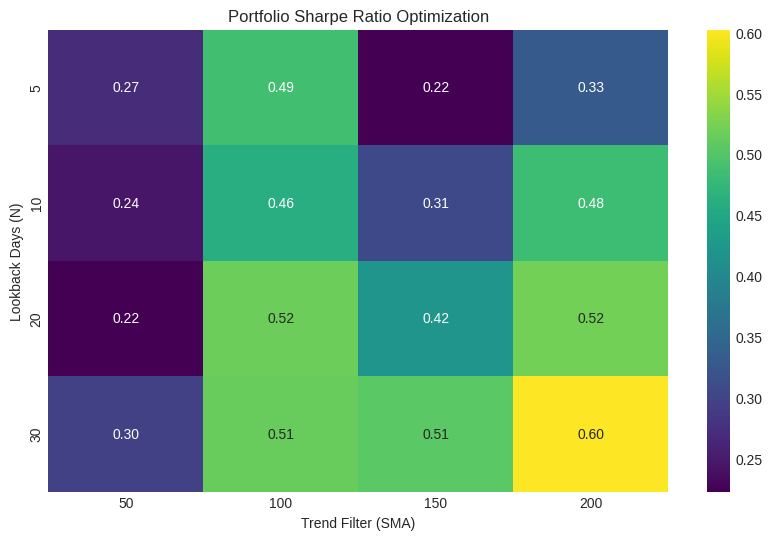

In [4]:
import yfinance as yf
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from pandas.tseries.holiday import USFederalHolidayCalendar
from typing import Dict, List, Tuple

def load_data_store(assets: List[str], start_date: str, end_date: str) -> Dict[str, pd.DataFrame]:
    """
    Tải và làm sạch dữ liệu cho danh sách tài sản.
    Lưu trữ dưới dạng Dictionary để truy xuất nhanh trong quá trình Grid Search.
    """
    data_store = {}
    print(f"Loading data for {len(assets)} assets from {start_date} to {end_date}...")

    for symbol in assets:
        try:
            df = yf.download(symbol, start=start_date, end=end_date, progress=False, auto_adjust=False)

            if isinstance(df.columns, pd.MultiIndex):
                df.columns = df.columns.get_level_values(0)

            df.columns = df.columns.str.lower()
            df.index = df.index.tz_localize(None)
            df = df.resample('1D').last().ffill()

            # Chỉ chấp nhận dữ liệu có độ dài tối thiểu 1 năm
            if len(df) > 365:
                data_store[symbol] = df

        except Exception as e:
            print(f"Error loading {symbol}: {e}")

    return data_store

def calculate_asset_pnl(df: pd.DataFrame, n_days: int, sma_period: int, fee: float = 0.001) -> pd.Series:
    """
    Tính toán chuỗi lợi nhuận ròng (Net PnL Series) cho một tài sản đơn lẻ
    dựa trên tham số Strategy được truyền vào.
    """
    data = df.copy()

    # Tính toán Indicators
    data['n_high'] = data['close'].shift(1).rolling(window=n_days).max()
    data['sma'] = data['close'].rolling(window=sma_period).mean()

    # Xử lý ngày lễ
    cal = USFederalHolidayCalendar()
    holidays = cal.holidays(start=data.index.min(), end=data.index.max())

    # Tạo mask cho vùng giao dịch (Window: D-5 đến D+1)
    data['in_window'] = False
    idx_dates = data.index
    for h in holidays:
        mask = (idx_dates >= h + pd.Timedelta(days=-5)) & \
               (idx_dates <= h + pd.Timedelta(days=1))
        data.loc[mask, 'in_window'] = True

    # Logic vào lệnh: Window + Breakout + Uptrend
    entry_condition = (
        (data['in_window']) &
        (data['close'] > data['n_high']) &
        (data['close'] > data['sma'])
    )

    data['signal'] = np.where(entry_condition, 1, 0)

    # Tính PnL
    market_ret = data['close'].pct_change()
    strat_ret = data['signal'].shift(1) * market_ret

    # Trừ phí giao dịch khi thay đổi trạng thái
    trades = data['signal'].diff().abs()
    cost = trades * fee

    return strat_ret - cost

def run_grid_search(data_store: Dict[str, pd.DataFrame]) -> pd.DataFrame:
    """
    Thực hiện tối ưu hóa tham số trên toàn bộ danh mục (Portfolio Optimization).
    Giả định phân bổ vốn đều (Equal Weight).
    """
    # Không gian tham số (Parameter Space)
    n_options = [5, 10, 20, 30]
    sma_options = [50, 100, 150, 200]

    results = []
    total_combinations = len(n_options) * len(sma_options)
    print(f"Starting Grid Search on {total_combinations} combinations...")

    for n in n_options:
        for sma in sma_options:
            portfolio_returns = pd.DataFrame()

            # Tính PnL cho từng coin với bộ tham số hiện tại
            for symbol, df in data_store.items():
                net_ret = calculate_asset_pnl(df, n, sma)
                portfolio_returns[symbol] = net_ret

            # Tính lợi nhuận trung bình của Portfolio (Equal Weight)
            avg_portfolio_ret = portfolio_returns.mean(axis=1).fillna(0)

            # Tính các chỉ số đánh giá (Metrics)
            if avg_portfolio_ret.std() == 0:
                sharpe = 0
            else:
                sharpe = (avg_portfolio_ret.mean() / avg_portfolio_ret.std()) * np.sqrt(365)

            cum_ret = (1 + avg_portfolio_ret).cumprod()
            total_ret = cum_ret.iloc[-1] - 1
            mdd = (cum_ret / cum_ret.cummax() - 1).min()

            results.append({
                'N_Days': n,
                'SMA_Period': sma,
                'Sharpe': sharpe,
                'Return': total_ret,
                'MDD': mdd
            })

    return pd.DataFrame(results)

def plot_heatmap(results_df: pd.DataFrame):
    """Vẽ biểu đồ nhiệt thể hiện Sharpe Ratio theo các tham số."""
    pivot_table = results_df.pivot(index='N_Days', columns='SMA_Period', values='Sharpe')

    plt.figure(figsize=(10, 6))
    sns.heatmap(pivot_table, annot=True, cmap='viridis', fmt='.2f')
    plt.title('Portfolio Sharpe Ratio Optimization')
    plt.ylabel('Lookback Days (N)')
    plt.xlabel('Trend Filter (SMA)')
    plt.show()

if __name__ == "__main__":
    # Cấu hình
    ASSETS = ['BTC-USD', 'ETH-USD', 'BNB-USD', 'SOL-USD', 'ADA-USD', 'LTC-USD']
    START_DATE = '2018-01-01'
    END_DATE = '2023-01-01' # Chỉ dùng In-Sample để Tuning

    # 1. Tải dữ liệu
    data_store = load_data_store(ASSETS, START_DATE, END_DATE)

    if data_store:
        # 2. Chạy Grid Search
        df_results = run_grid_search(data_store)

        # 3. Hiển thị kết quả tốt nhất
        df_sorted = df_results.sort_values(by='Sharpe', ascending=False)

        print("\nTop 5 Parameter Configurations:")
        pd.options.display.float_format = '{:.4f}'.format
        print(df_sorted.head(5))

        # 4. Vẽ biểu đồ
        plot_heatmap(df_results)
    else:
        print("No data loaded. Please check your internet connection or asset symbols.")

Loading data for 6 assets from 2022-01-01 to 2024-12-31...

 PERFORMANCE REPORT (N=30, SMA=50)
      Metric  Value
Total Return 41.42%
        CAGR 12.26%
Max Drawdown -6.60%
Sharpe Ratio 1.2582

Đang vẽ biểu đồ so sánh Strategy vs Bitcoin...


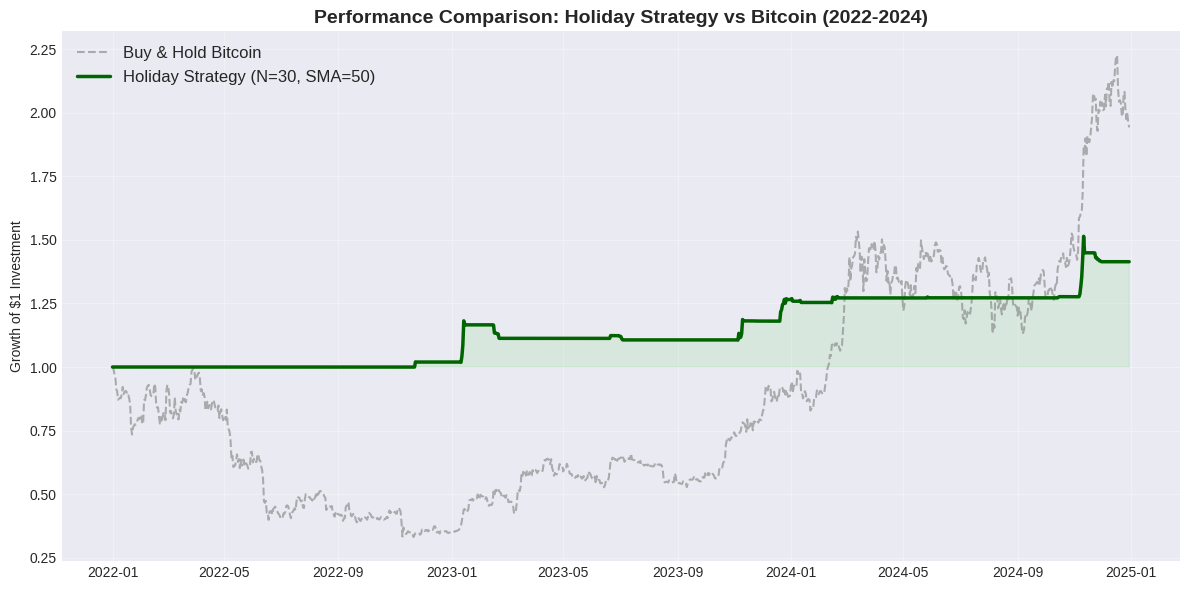

In [3]:
import yfinance as yf
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from pandas.tseries.holiday import USFederalHolidayCalendar
from typing import Dict, List, Tuple

# --- 1. DATA LOADER ---
def load_data_store(assets: List[str], start_date: str, end_date: str) -> Dict[str, pd.DataFrame]:
    """Tải và làm sạch dữ liệu."""
    data_store = {}
    print(f"Loading data for {len(assets)} assets from {start_date} to {end_date}...")

    for symbol in assets:
        try:
            df = yf.download(symbol, start=start_date, end=end_date, progress=False, auto_adjust=False)
            if isinstance(df.columns, pd.MultiIndex):
                df.columns = df.columns.get_level_values(0)
            df.columns = df.columns.str.lower()
            df.index = df.index.tz_localize(None)
            df = df.resample('1D').last().ffill()
            if len(df) > 365:
                data_store[symbol] = df
        except Exception as e:
            print(f"Error loading {symbol}: {e}")
    return data_store

# --- 2. STRATEGY LOGIC ---
def calculate_asset_pnl(df: pd.DataFrame, n_days: int, sma_period: int, fee: float = 0.001) -> pd.Series:
    """Tính toán chuỗi lợi nhuận ròng."""
    data = df.copy()
    data['n_high'] = data['close'].shift(1).rolling(window=n_days).max()
    data['sma'] = data['close'].rolling(window=sma_period).mean()

    cal = USFederalHolidayCalendar()
    holidays = cal.holidays(start=data.index.min(), end=data.index.max())

    data['in_window'] = False
    idx_dates = data.index
    for h in holidays:
        mask = (idx_dates >= h + pd.Timedelta(days=-5)) & \
               (idx_dates <= h + pd.Timedelta(days=1))
        data.loc[mask, 'in_window'] = True

    entry_condition = (
        (data['in_window']) &
        (data['close'] > data['n_high']) &
        (data['close'] > data['sma'])
    )

    data['signal'] = np.where(entry_condition, 1, 0)

    market_ret = data['close'].pct_change()
    strat_ret = data['signal'].shift(1) * market_ret
    trades = data['signal'].diff().abs()
    cost = trades * fee

    return strat_ret - cost

# --- 3. GRID SEARCH ---
def run_grid_search(data_store: Dict[str, pd.DataFrame]) -> pd.DataFrame:
    n_options = [5, 10, 20, 30]
    sma_options = [50, 100, 150, 200]
    results = []

    print(f"Starting Grid Search on {len(n_options)*len(sma_options)} combinations...")

    for n in n_options:
        for sma in sma_options:
            portfolio_returns = pd.DataFrame()
            for symbol, df in data_store.items():
                portfolio_returns[symbol] = calculate_asset_pnl(df, n, sma)

            avg_ret = portfolio_returns.mean(axis=1).fillna(0)

            if avg_ret.std() == 0: sharpe = 0
            else: sharpe = (avg_ret.mean() / avg_ret.std()) * np.sqrt(365)

            cum_ret = (1 + avg_ret).cumprod()
            total_ret = cum_ret.iloc[-1] - 1
            mdd = (cum_ret / cum_ret.cummax() - 1).min()

            results.append({'N_Days': n, 'SMA_Period': sma, 'Sharpe': sharpe, 'Return': total_ret, 'MDD': mdd})

    return pd.DataFrame(results)

# --- 4. VISUALIZATION FUNCTIONS ---
def plot_heatmap(results_df: pd.DataFrame):
    pivot_table = results_df.pivot(index='N_Days', columns='SMA_Period', values='Sharpe')
    plt.figure(figsize=(10, 6))
    sns.heatmap(pivot_table, annot=True, cmap='viridis', fmt='.2f')
    plt.title('Portfolio Sharpe Ratio Optimization')
    plt.show()

def show_specific_performance(data_store: Dict[str, pd.DataFrame], n: int, sma: int):
    portfolio_returns = pd.DataFrame()
    for symbol, df in data_store.items():
        portfolio_returns[symbol] = calculate_asset_pnl(df, n, sma)

    avg_ret = portfolio_returns.mean(axis=1).fillna(0)
    cum_ret = (1 + avg_ret).cumprod()

    total_return = cum_ret.iloc[-1] - 1
    mdd = (cum_ret / cum_ret.cummax() - 1).min()
    sharpe = (avg_ret.mean() / avg_ret.std()) * np.sqrt(365) if avg_ret.std() != 0 else 0

    # Tính CAGR
    days = (avg_ret.index[-1] - avg_ret.index[0]).days
    cagr = (cum_ret.iloc[-1]) ** (365 / days) - 1 if days > 0 else 0

    print(f"\n{'='*40}")
    print(f" PERFORMANCE REPORT (N={n}, SMA={sma})")
    print(f"{'='*40}")
    metrics = pd.DataFrame({
        'Metric': ['Total Return', 'CAGR', 'Max Drawdown', 'Sharpe Ratio'],
        'Value': [f"{total_return:.2%}", f"{cagr:.2%}", f"{mdd:.2%}", f"{sharpe:.4f}"]
    })
    print(metrics.to_string(index=False))
    print(f"{'='*40}\n")

# --- 5. NEW CHART: STRATEGY VS BTC ---
def plot_equity_comparison(data_store: Dict[str, pd.DataFrame], n: int, sma: int):
    """Vẽ biểu đồ so sánh Chiến lược vs Buy & Hold Bitcoin."""

    # A. Tính Equity của Chiến lược (Strategy)
    portfolio_returns = pd.DataFrame()
    for symbol, df in data_store.items():
        portfolio_returns[symbol] = calculate_asset_pnl(df, n, sma)

    strat_ret = portfolio_returns.mean(axis=1).fillna(0)
    strat_equity = (1 + strat_ret).cumprod()

    # B. Tính Equity của Bitcoin (Benchmark)
    if 'BTC-USD' in data_store:
        btc_df = data_store['BTC-USD']
        btc_ret = btc_df['close'].pct_change().fillna(0)
        # Cắt dữ liệu BTC cho khớp ngày bắt đầu của Strategy (do Strategy bị mất ngày đầu tính SMA)
        start_idx = strat_equity.index[0]
        btc_ret = btc_ret.loc[start_idx:]
        btc_equity = (1 + btc_ret).cumprod()

        # Chuẩn hóa về cùng mốc bắt đầu là 1 (để dễ so sánh)
        btc_equity = btc_equity / btc_equity.iloc[0]
        strat_equity = strat_equity / strat_equity.iloc[0]
    else:
        print("Không tìm thấy BTC-USD để so sánh.")
        return

    # C. Vẽ Biểu đồ
    plt.style.use('seaborn-v0_8-darkgrid')
    plt.figure(figsize=(12, 6))

    # Đường Bitcoin (Màu xám/cam)
    plt.plot(btc_equity.index, btc_equity, color='gray', linestyle='--', alpha=0.6, label='Buy & Hold Bitcoin')

    # Đường Chiến lược (Màu xanh đậm - Nổi bật)
    plt.plot(strat_equity.index, strat_equity, color='#006400', linewidth=2.5, label=f'Holiday Strategy (N={n}, SMA={sma})')

    # Tô màu vùng vượt trội
    plt.fill_between(strat_equity.index, strat_equity, 1, where=(strat_equity >= 1), color='#32CD32', alpha=0.1)

    plt.title('Performance Comparison: Holiday Strategy vs Bitcoin (2022-2024)', fontsize=14, fontweight='bold')
    plt.ylabel('Growth of $1 Investment')
    plt.legend(fontsize=12)
    plt.grid(True, alpha=0.3)

    # Định dạng trục X
    plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))

    plt.tight_layout()
    plt.show()

# --- MAIN ---
if __name__ == "__main__":
    ASSETS = ['BTC-USD', 'ETH-USD', 'BNB-USD', 'SOL-USD', 'ADA-USD', 'LTC-USD']
    START_DATE = '2022-01-01'
    END_DATE = '2024-12-31'

    data_store = load_data_store(ASSETS, START_DATE, END_DATE)

    if data_store:
        # 1. Grid Search
        # df_results = run_grid_search(data_store) # Bỏ comment nếu muốn chạy lại tìm tham số

        # 2. Hiển thị bảng số liệu chi tiết
        show_specific_performance(data_store, n=30, sma=50)

        # 3. VẼ BIỂU ĐỒ SO SÁNH (QUAN TRỌNG NHẤT)
        print("Đang vẽ biểu đồ so sánh Strategy vs Bitcoin...")
        plot_equity_comparison(data_store, n=30, sma=50)

    else:
        print("No data loaded.")